##### **Błażej Klepacki, 331389**

In [1]:
import gudhi
import numpy as np
import galois
import itertools
import matplotlib.pyplot as plt
from math import comb
from time import perf_counter

##### Funkcje z Lab4: macierz brzegu, f, r, betti

In [2]:
def simplices(st, k):
    return sorted(tuple(s) for s, _ in st.get_skeleton(k) if len(s) == k + 1)

def boundary_matrix(st, k, p=2):
    cols = simplices(st, k)
    rows = simplices(st, k - 1)
    index = {tau: i for i, tau in enumerate(rows)}
    D = np.zeros((len(index), len(cols)), dtype=int)

    for j, sigma in enumerate(cols):
        for i in range(len(sigma)):
            tau = sigma[:i] + sigma[i + 1:]
            D[index[tau], j] = (-1) ** i % p
    return D

In [3]:
def f(sk, i):
    return len(simplices(sk, i))

In [4]:
def r(st, k, p=2):
    if k <= 0 or k > st.dimension():
        return 0
    GF2 = galois.GF(p)
    return np.linalg.matrix_rank(GF2(boundary_matrix(st, k, p)))

In [5]:
def betti(sk, p=2):
    return [f(sk, i) - r(sk, i, p) - r(sk, i+1, p) for i in range(3)]

##### Chmury z wykładu i najmniejsza kula

chmura: najpierw losuję wszystkie $t_j$, potem szum

$\rho$ dla sympleksów wymiaru $\le 2$ z wykładu:
* krawędź: $\rho = \frac{1}{2}\|x - x'\|$
* trójkąt rozwartokątny ($c^2 \ge a^2 + b^2$ dla najdłuższego boku $c$): $\rho = c/2$
* trójkąt ostrokątny: okrąg opisany $R = \frac{abc}{4S}$, $S$ ze wzoru Herona

In [6]:
def chmura(n, sigma, seed=0):
    rng = np.random.default_rng(seed)
    t = rng.uniform(0, 2 * np.pi, n)
    return np.c_[np.cos(t), np.sin(t)] + rng.normal(0, sigma, (n, 2))

XA = chmura(60, 0.05)    # (A) z wykladu 5
XB = chmura(120, 0.1)    # (B) z wykladu 1

In [7]:
def rho(P):
    if len(P) == 1:
        return 0.
    if len(P) == 2:
        return np.linalg.norm(P[0] - P[1]) / 2

    a, b, c = sorted([np.linalg.norm(P[0] - P[1]),
                      np.linalg.norm(P[1] - P[2]),
                      np.linalg.norm(P[0] - P[2])])
    if c**2 >= a**2 + b**2:     # rozwartokatny
        return c / 2
    p = (a + b + c) / 2
    S = np.sqrt(p * (p - a) * (p - b) * (p - c))    # Heron
    return a * b * c / (4 * S)                      # okrag opisany

##### **Zadanie 1**

sprawdzam wszystkie podzbiory 1-, 2- i 3-elementowe i wstawiam te, dla których $\rho < r$

In [8]:
def cech(X, r):
    st = gudhi.SimplexTree()
    for k in range(1, 4):
        for sigma in itertools.combinations(range(len(X)), k):
            if rho(X[list(sigma)]) < r:
                st.insert(list(sigma))
    return st

rozgrzewka galois (kompilacja), przy okazji sprawdzenie z wykładem: dla (A) i $r = 0.3$ ma wyjść $f = (60, 332, 835)$, $\beta = (1, 1)$

In [9]:
K = cech(XA, 0.3)
print(f'f = {K.num_simplices_by_dimension()}, beta = {betti(K)[:2]}')

f = [ 60 332 835], beta = [1, 1]


**zadanie 1a**

In [10]:
def tabela(X, rs):
    wyniki = []
    for rr in rs:
        start = perf_counter()
        K = cech(X, rr)
        t_bud = perf_counter() - start

        start = perf_counter()
        b = betti(K)
        t_bet = perf_counter() - start

        fv = [f(K, 0), f(K, 1), f(K, 2)]
        wyniki.append((rr, b[0], b[1], t_bud, t_bet))
        print(f'r = {rr:.2f} | f = {str(fv):20} | beta0 = {b[0]:3}, beta1 = {b[1]:2} | '
              f'budowa: {t_bud:.3f} s | betti: {t_bet:.3f} s')
    return wyniki


def rysuj(wyniki, tytul):
    rs, b0, b1, t_bud, t_bet = zip(*wyniki)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(rs, b0, 'o-')
    axes[0].set(xlabel='r', title=r'$\beta_0$')
    axes[1].plot(rs, b1, 'o-', color='C1')
    axes[1].set(xlabel='r', title=r'$\beta_1$')
    axes[2].plot(rs, t_bud, 'o-', label='budowa kompleksu')
    axes[2].plot(rs, t_bet, 'o-', label='liczby Bettiego')
    axes[2].set(xlabel='r', ylabel='czas [s]', title='czasy')
    axes[2].legend()
    for ax in axes:
        ax.grid(alpha=0.25)
    fig.suptitle(tytul)
    fig.tight_layout()
    plt.show()

r = 0.05 | f = [60, 37, 9]          | beta0 =  31, beta1 =  0 | budowa: 0.534 s | betti: 0.009 s
r = 0.10 | f = [60, 91, 58]         | beta0 =  10, beta1 =  0 | budowa: 0.554 s | betti: 0.028 s
r = 0.15 | f = [60, 144, 146]       | beta0 =   3, beta1 =  0 | budowa: 0.579 s | betti: 0.042 s
r = 0.20 | f = [60, 205, 298]       | beta0 =   1, beta1 =  1 | budowa: 0.560 s | betti: 0.064 s
r = 0.25 | f = [60, 265, 515]       | beta0 =   1, beta1 =  1 | budowa: 0.534 s | betti: 0.089 s
r = 0.30 | f = [60, 332, 835]       | beta0 =   1, beta1 =  1 | budowa: 0.533 s | betti: 0.114 s
r = 0.35 | f = [60, 394, 1183]      | beta0 =   1, beta1 =  1 | budowa: 0.578 s | betti: 0.136 s
r = 0.40 | f = [60, 443, 1514]      | beta0 =   1, beta1 =  1 | budowa: 0.556 s | betti: 0.170 s
r = 0.45 | f = [60, 496, 1900]      | beta0 =   1, beta1 =  1 | budowa: 0.563 s | betti: 0.193 s
r = 0.50 | f = [60, 570, 2533]      | beta0 =   1, beta1 =  1 | budowa: 0.549 s | betti: 0.238 s
r = 0.55 | f = [60, 634, 3147]

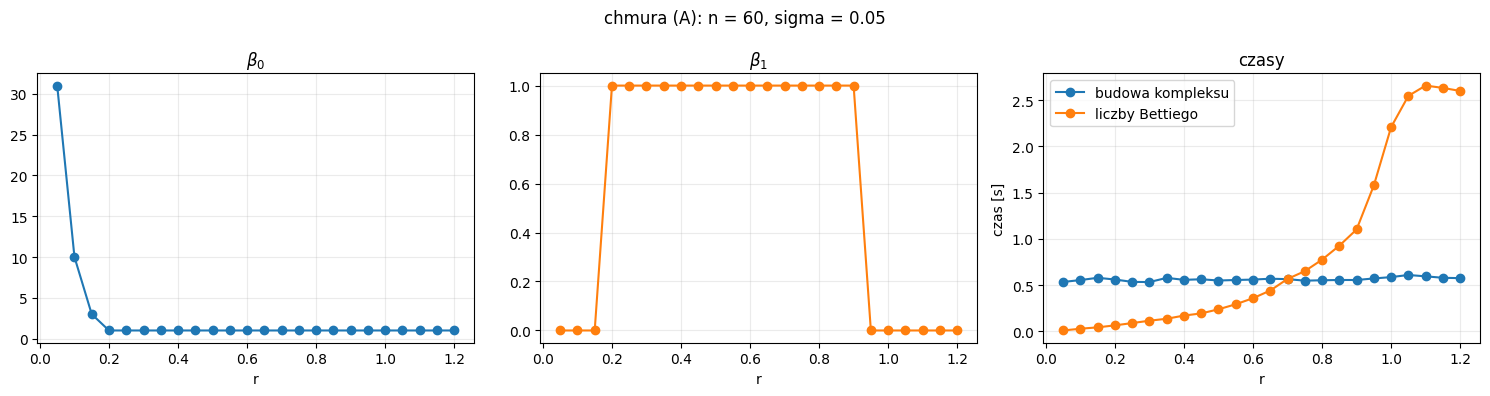

In [11]:
wyniki_A = tabela(XA, np.round(np.arange(0.05, 1.21, 0.05), 2))
rysuj(wyniki_A, 'chmura (A): n = 60, sigma = 0.05')

czas budowy jest prawie stały (ok. 0.55 s), bo `cech` zawsze sprawdza te same podzbiory, $r$ zmienia tylko wynik testu. czas betti rośnie z $r$ (od 0.009 s do ok. 2.6 s), bo rośnie $f$, a z nim macierze brzegu. od $r = 1.15$ w kompleksie są już wszystkie pary i trójki ($\binom{60}{2} = 1770$, $\binom{60}{3} = 34220$)

**zadanie 1b**

- okrąg, czyli $\beta = (1, 1)$, jest dla $r$ od 0.20 do 0.90
- poniżej ($r \le 0.15$) kule nie łączą wszystkich sąsiadów: $\beta_0 = 31, 10, 3$, chmura rozpada się na kawałki łuków i pętla się nie zamyka
- powyżej ($r \ge 0.95$) $\beta_1 = 0$: kule sięgają środka okręgu i trójkąty zaklejają dziurę, kompleks jest jak dysk
- twierdzenie z wykładu ($r < \sqrt{3/5} \approx 0.775$ i dostatecznie gęsta próbka) jest tylko warunkiem wystarczającym, a do tego formalnie nie działa przy szumie. faktyczny przedział wyszedł szerszy

**zadanie 1c**

r = 0.05 | f = [120, 79, 18]        | beta0 =  57, beta1 =  0 | budowa: 4.474 s | betti: 0.024 s
r = 0.10 | f = [120, 315, 375]      | beta0 =   4, beta1 =  2 | budowa: 4.503 s | betti: 0.097 s
r = 0.15 | f = [120, 622, 1620]     | beta0 =   2, beta1 =  1 | budowa: 4.639 s | betti: 0.218 s
r = 0.20 | f = [120, 889, 3369]     | beta0 =   1, beta1 =  1 | budowa: 4.287 s | betti: 0.406 s
r = 0.25 | f = [120, 1183, 6021]    | beta0 =   1, beta1 =  1 | budowa: 4.546 s | betti: 0.707 s
r = 0.30 | f = [120, 1425, 8791]    | beta0 =   1, beta1 =  1 | budowa: 4.579 s | betti: 0.940 s
r = 0.35 | f = [120, 1671, 12103]   | beta0 =   1, beta1 =  1 | budowa: 4.382 s | betti: 1.442 s
r = 0.40 | f = [120, 1929, 15976]   | beta0 =   1, beta1 =  1 | budowa: 4.413 s | betti: 1.810 s
r = 0.45 | f = [120, 2193, 20518]   | beta0 =   1, beta1 =  1 | budowa: 4.406 s | betti: 2.581 s
r = 0.50 | f = [120, 2454, 25686]   | beta0 =   1, beta1 =  1 | budowa: 4.342 s | betti: 3.350 s


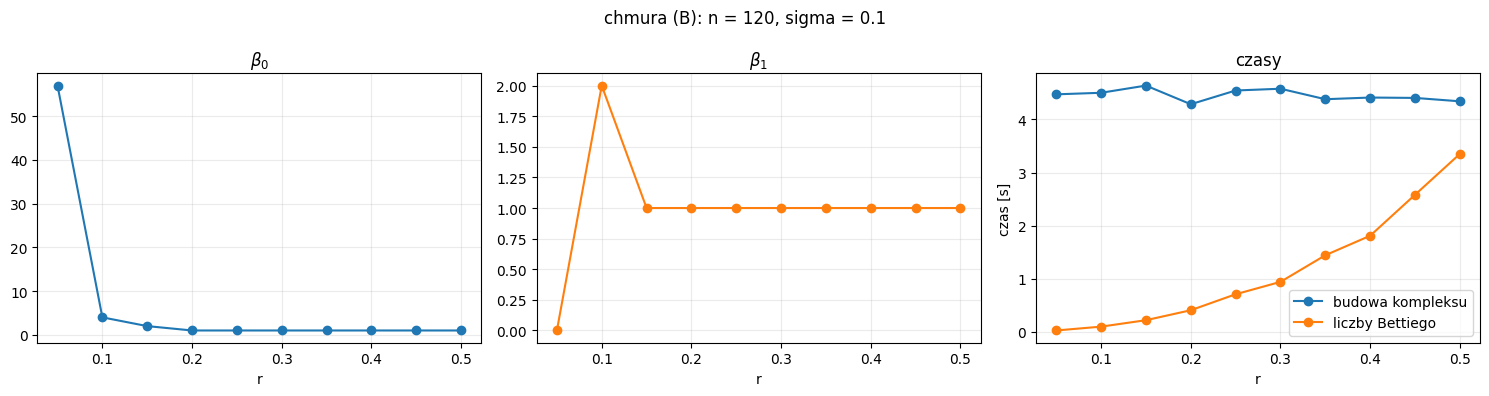

In [12]:
wyniki_B = tabela(XB, np.round(np.arange(0.05, 0.51, 0.05), 2))
rysuj(wyniki_B, 'chmura (B): n = 120, sigma = 0.1')

**Wnioski do zadania 1**

- dla (B) $\beta = (1, 1)$ dla $r$ od 0.20 do 0.50, czyli przedział zaczyna się tam, gdzie w (A)
- różnica jest poniżej: dla $r = 0.10$ wychodzi $\beta_1 = 2$, a dla $r = 0.15$ $\beta = (2, 1)$. szum $\sigma = 0.1$ jest dwa razy większy, punkty są rozrzucone w poprzek okręgu i tworzą małe fałszywe pętle, a pojedyncze odstające punkty długo zostają osobnymi składowymi. w (A) fałszywych pętli nie było
- większy szum wpycha też punkty bliżej środka, więc dziura zakleiłaby się przy mniejszym $r$ niż w (A) (tego już nie widać, bo liczymy tylko do 0.5)
- budowa w (B) trwa ok. 4.5 s, czyli ok. 8 razy dłużej niż w (A): 2 razy więcej punktów, a podzbiorów ok. $2^3$ razy więcej

##### **Zadanie 2**

In [13]:
ns = [30, 60, 120, 240]
chmury = {n: chmura(n, 0.05) for n in ns}
kompleksy = {}
t_bud, t_bet = [], []

for n in ns:
    start = perf_counter()
    K = cech(chmury[n], 0.3)
    t_bud.append(perf_counter() - start)

    start = perf_counter()
    b = betti(K)
    t_bet.append(perf_counter() - start)

    kompleksy[n] = K
    print(f'n = {n:3} | f = {str(K.num_simplices_by_dimension()):22} | beta = {b[:2]} | '
          f'budowa: {t_bud[-1]:7.3f} s | betti: {t_bet[-1]:7.3f} s')

n =  30 | f = [ 30  91 140]          | beta = [1, 0] | budowa:   0.074 s | betti:   0.029 s
n =  60 | f = [ 60 332 835]          | beta = [1, 1] | budowa:   0.534 s | betti:   0.097 s
n = 120 | f = [ 120 1433 8743]       | beta = [1, 1] | budowa:   4.483 s | betti:   0.983 s
n = 240 | f = [  240  5551 64015]    | beta = [1, 1] | budowa:  35.270 s | betti:  19.448 s


**zadanie 2a**

jeśli $t \approx C n^a$, to w skali log-log jest to prosta o nachyleniu $a$

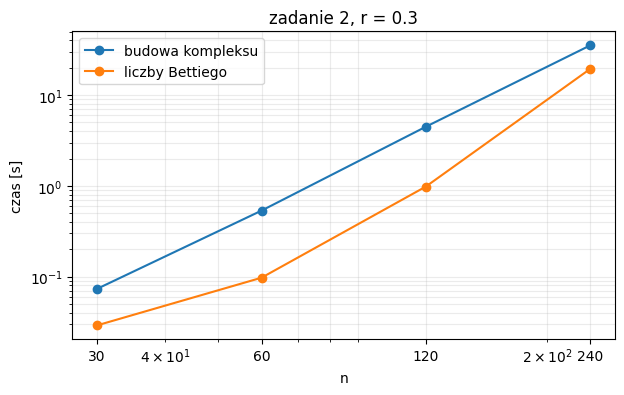

budowa | nachylenie ze wszystkich: 2.98 | z n = 120, 240: 2.98
betti  | nachylenie ze wszystkich: 3.15 | z n = 120, 240: 4.31


In [14]:
def nachylenie(ns, ts):
    return np.polyfit(np.log(ns), np.log(ts), 1)[0]

plt.figure(figsize=(7, 4))
plt.loglog(ns, t_bud, 'o-', label='budowa kompleksu')
plt.loglog(ns, t_bet, 'o-', label='liczby Bettiego')
plt.xlabel('n')
plt.ylabel('czas [s]')
plt.title('zadanie 2, r = 0.3')
plt.xticks(ns, ns)
plt.legend()
plt.grid(alpha=0.25, which='both')
plt.show()

for nazwa, ts in [('budowa', t_bud), ('betti', t_bet)]:
    print(f'{nazwa:6} | nachylenie ze wszystkich: {nachylenie(ns, ts):.2f} | z n = 120, 240: {nachylenie(ns[2:], ts[2:]):.2f}')

- budowa: nachylenie ok. 3, czyli $t \sim n^3$ (podwojenie $n$ wydłuża ok. 8 razy)
- betti: z dwóch ostatnich punktów nachylenie ok. 4.3 i rośnie (dla małych $n$ dominuje narzut), w granicy powinno dojść do ok. 5. powód: $f_1 \sim n^2$, $f_2 \sim n^3$ (widać w tabeli, przy podwojeniu $n$ $f_1$ rośnie ok. 4 razy, a $f_2$ ok. 8 razy), a gęsta macierz $\partial_2$ ma $f_1 \cdot f_2 \sim n^5$ wyrazów

**zadanie 2b**

`cech` sprawdza każdy podzbiór co najwyżej 3-elementowy, niezależnie od $r$:
$$\binom{n}{1} + \binom{n}{2} + \binom{n}{3} \approx \frac{n^3}{6}$$
a dla każdego liczy $\rho$ w stałym czasie, więc czas powinien rosnąć jak $n^3$. sprawdzenie, czy czas na jeden podzbiór jest stały:

In [15]:
for n, t in zip(ns, t_bud):
    ile = n + comb(n, 2) + comb(n, 3)
    print(f'n = {n:3} | podzbiory: {ile:8} | czas / podzbior: {t / ile * 1e6:.2f} mikrosekund')

n =  30 | podzbiory:     4525 | czas / podzbior: 16.25 mikrosekund
n =  60 | podzbiory:    36050 | czas / podzbior: 14.81 mikrosekund
n = 120 | podzbiory:   288100 | czas / podzbior: 15.56 mikrosekund
n = 240 | podzbiory:  2304200 | czas / podzbior: 15.31 mikrosekund


**zadanie 2c**

budowa: liczba podzbiorów razy czas na podzbiór z $n = 240$. liczby Bettiego: $t(240) \cdot (n / 240)^a$ z nachyleniem z dwóch ostatnich punktów

In [16]:
na_podzbior = t_bud[-1] / (240 + comb(240, 2) + comb(240, 3))
a = nachylenie(ns[2:], t_bet[2:])

for n in [1000, 10**4]:
    t_b = (n + comb(n, 2) + comb(n, 3)) * na_podzbior
    t_h = t_bet[-1] * (n / 240) ** a
    print(f'n = {n:5} | budowa: {t_b / 3600:7.1f} h | betti: {t_h / 3600:8.1f} h')

n =  1000 | budowa:     0.7 h | betti:      2.5 h
n = 10000 | budowa:   708.7 h | betti:  50924.5 h


- $n = 1000$: budowa ok. 40 minut. betti z ekstrapolacji ok. 2.5 h (raczej zaniżone, bo nachylenie jeszcze rośnie), ale w praktyce się nie da: $f_1 \approx 5551 \cdot (1000/240)^2 \approx 10^5$, $f_2 \approx 64015 \cdot (1000/240)^3 \approx 4.6 \cdot 10^6$, więc macierz $\partial_2$ miałaby ok. $4 \cdot 10^{11}$ wyrazów, czyli tysiące GB
- $n = 10^4$: sama budowa ok. 700 h (ok. 30 dni), a betti ok. 51 tys. h (ok. 6 lat), bez szans

**zadanie 2d**

$\beta$ są w tabeli wyżej. żeby zobaczyć, czy próbka jest dość gęsta, liczę jak daleko od chmury jest najdalszy punkt okręgu (w twierdzeniu z wykładu ma być $< r/2 = 0.15$)

In [17]:
def najdalszy_punkt_okregu(X, m=10000):
    s = np.linspace(0, 2 * np.pi, m, endpoint=False)
    M = np.c_[np.cos(s), np.sin(s)]
    odl = np.linalg.norm(M[:, None, :] - X[None, :, :], axis=2)
    return odl.min(axis=1).max()

for n in ns:
    print(f'n = {n:3} | najdalszy punkt okregu: {najdalszy_punkt_okregu(chmury[n]):.3f}')

n =  30 | najdalszy punkt okregu: 0.320
n =  60 | najdalszy punkt okregu: 0.183
n = 120 | najdalszy punkt okregu: 0.135
n = 240 | najdalszy punkt okregu: 0.084


**Wnioski do zadania 2**

- dla $n = 30$ wychodzi $\beta = (1, 0)$, czyli okręgu nie widać. najdalszy punkt okręgu jest 0.32 od chmury, więc w próbce jest przerwa szeroka na ok. 0.64, większa niż $2r = 0.6$. żadna krawędź jej nie przeskakuje i kompleks to jeden łuk
- dla $n \ge 60$ wychodzi okrąg. dla 120 i 240 warunek gęstości z twierdzenia ($< r/2 = 0.15$) jest spełniony, dla 60 nie (0.183), a okrąg i tak wyszedł
- czyli nie zawsze: przy ustalonym $r$ próbka musi być dość gęsta, a punkty są losowe, więc przy małym $n$ łatwo o dużą przerwę

##### **Zadanie 3**

z wykładu: ściany sympleksu Čecha też są w kompleksie, więc sprawdzam tylko kandydatów, których wszystkie ściany już są:
* krawędzie: $\{i, j\}$, gdy $\|x_i - x_j\| < 2r$
* trójkąty: krawędź $\{i, j\}$ rozszerzam tylko o $k \in N^+(i) \cap N^+(j)$ ($N^+(i)$ to sąsiedzi $i$ o większym numerze) i dopiero dla nich liczę $\rho$

In [18]:
def cech_szybki(X, r):
    n = len(X)
    st = gudhi.SimplexTree()
    for i in range(n):
        st.insert([i])

    # krawedzie i N+(i)
    sasiedzi = [set() for _ in range(n)]
    for i in range(n):
        for j in range(i + 1, n):
            if np.linalg.norm(X[i] - X[j]) < 2 * r:
                st.insert([i, j])
                sasiedzi[i].add(j)

    # trojkaty tylko z kandydatow
    for i in range(n):
        for j in sasiedzi[i]:
            for k in sasiedzi[i] & sasiedzi[j]:
                if rho(X[[i, j, k]]) < r:
                    st.insert([i, j, k])
    return st

n =  30 | budowa: 0.005 s (wczesniej 0.074 s) | ten sam kompleks: True
n =  60 | budowa: 0.026 s (wczesniej 0.534 s) | ten sam kompleks: True
n = 120 | budowa: 0.171 s (wczesniej 4.483 s) | ten sam kompleks: True
n = 240 | budowa: 1.184 s (wczesniej 35.270 s) | ten sam kompleks: True
nachylenie: ze wszystkich 2.67, z n = 120, 240: 2.79


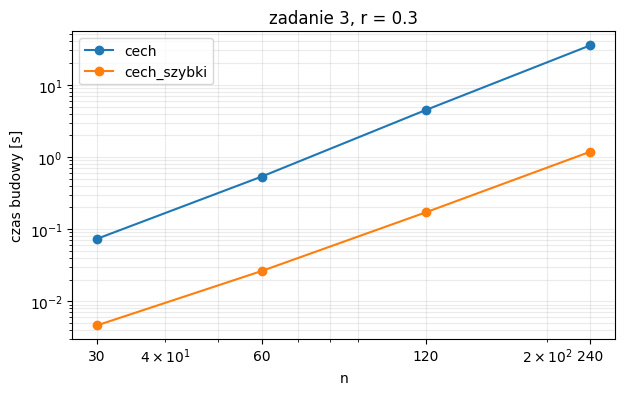

In [19]:
t_szyb = []
for n in ns:
    start = perf_counter()
    K = cech_szybki(chmury[n], 0.3)
    t_szyb.append(perf_counter() - start)
    takie_same = all(simplices(K, k) == simplices(kompleksy[n], k) for k in range(3))
    print(f'n = {n:3} | budowa: {t_szyb[-1]:.3f} s (wczesniej {t_bud[ns.index(n)]:.3f} s) | ten sam kompleks: {takie_same}')

print(f'nachylenie: ze wszystkich {nachylenie(ns, t_szyb):.2f}, z n = 120, 240: {nachylenie(ns[2:], t_szyb[2:]):.2f}')

plt.figure(figsize=(7, 4))
plt.loglog(ns, t_bud, 'o-', label='cech')
plt.loglog(ns, t_szyb, 'o-', label='cech_szybki')
plt.xlabel('n')
plt.ylabel('czas budowy [s]')
plt.title('zadanie 3, r = 0.3')
plt.xticks(ns, ns)
plt.legend()
plt.grid(alpha=0.25, which='both')
plt.show()

**Wnioski do zadania 3**

- `cech_szybki` daje te same kompleksy, a dla $n = 240$ jest ok. 30 razy szybszy (1.18 s zamiast 35 s)
- czas dalej rośnie jak $n^3$ (nachylenie z dwóch ostatnich punktów ok. 2.8, ze wszystkich trochę mniej, bo dla małych $n$ to milisekundy i narzut), zmieniła się tylko stała
- powód: przy stałym $r$ każdy punkt ma sąsiadów proporcjonalnie do $n$, więc kandydatów na trójkąty jest $\sim n^3$, a prawie wszyscy przechodzą test $\rho$ (punkty z krótkiego łuku dają trójkąty rozwartokątne). sam kompleks ma $f_2 \sim n^3$ trójkątów i każdy trzeba wstawić, więc przy stałym $r$ szybciej niż $n^3$ się nie da